# Import modules

In [1]:
import datetime
import itertools
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from tx_fast_hydrology.muskingum import Muskingum, ModelCollection, Connection
from tx_fast_hydrology.simulation import AsyncSimulation
from tx_fast_hydrology.da import KalmanFilter
import matplotlib.backends.backend_pdf as pdf
from collections import defaultdict

In [2]:
# Define model file input path
input_path = '../data/travis-county-lo-res-model-partitioned.json'
# Load model collection from file
model_collection = ModelCollection.from_file(input_path)

# Example implementation of timelagged ensemble

In [3]:
# Data structure for storing time-lagged ensembles

class FixSizedDict(dict):
    def __init__(self, *args, maxlen=7, **kwargs):
        self._maxlen = maxlen
        super().__init__(*args, **kwargs)

    def __setitem__(self, key, value):
        dict.__setitem__(self, key, value)
        if self._maxlen > 0:
            if len(self) > self._maxlen:
                self.pop(next(iter(self)))

In [4]:
# Define path for NWM forcings
forcing_path = '../data/20220822_event'
# Date range to load
date_list = pd.date_range('20220822', '20220824', freq='h', tz='utc')[:-1]

# Loop through HDF5 files and load streamflows into timelagged ensemble
timelagged_means = {}
ensembles = FixSizedDict(maxlen=18)
for date in date_list:
    date_str = date.strftime('%Y%m%d%H')
    streamflow = pd.read_hdf(f'{forcing_path}/{date_str}.h5', key='short_range__streamflow')
    # Append to ensemble
    ensembles[date] = streamflow
    current_ensemble = pd.concat(list(ensembles.values()))
    # Note that we are using the mean of the ensemble, but other statistics (max, min, median) are valid
    timelagged_mean = current_ensemble.groupby(current_ensemble.index).mean()
    timelagged_means[date] = timelagged_mean

In [5]:
# Loop through HDF5 files and load all short range forecasts
all_forecasts = {}
for date in date_list:
    date_str = date.strftime('%Y%m%d%H')
    streamflow = pd.read_hdf(f'{forcing_path}/{date_str}.h5', key='short_range__streamflow')
    all_forecasts[date] = streamflow

In [6]:
# Loop through HDF5 files and load streamflow from no-da run
streamflows = []
for date in date_list:
    date_str = date.strftime('%Y%m%d%H')
    streamflow = pd.read_hdf(f'{forcing_path}/{date_str}.h5', key='no_data_assimilation__streamflow')
    streamflows.append(streamflow)
# Concatenate all forcings into single dataframe
streamflow = pd.concat(streamflows)

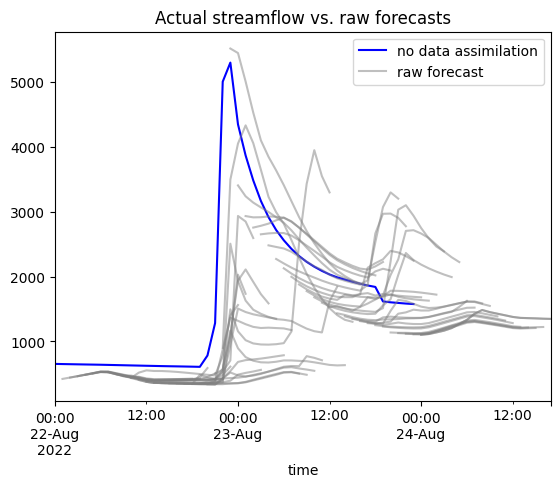

In [7]:
# Plot no-da streamflow vs. raw forecasts
streamflow.groupby(streamflow.index).mean().sum(axis=1).plot(c='b', label='no data assimilation')
for date in all_forecasts:
    all_forecasts[date].sum(axis=1).plot(c='0.5', alpha=0.5)
all_forecasts[date].sum(axis=1).plot(c='0.5', alpha=0.5, label='raw forecast')
plt.title('Actual streamflow vs. raw forecasts')
plt.legend()

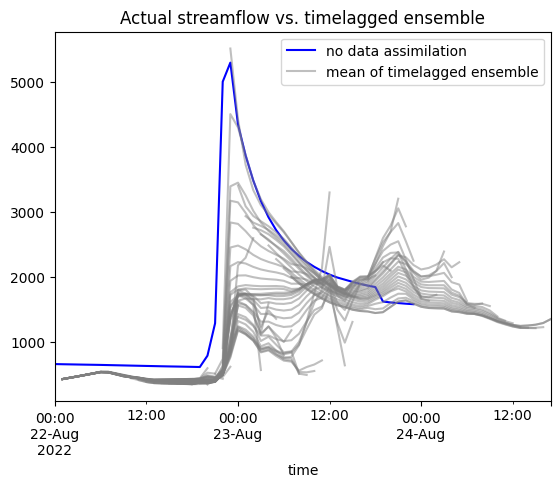

In [8]:
# Plot no-da streamflow vs. timelagged ensemble
streamflow.groupby(streamflow.index).mean().sum(axis=1).plot(c='b', label='no data assimilation')
for date in timelagged_means:
    timelagged_means[date].sum(axis=1).plot(c='0.5', alpha=0.5)
timelagged_means[date].sum(axis=1).plot(c='0.5', alpha=0.5, label='mean of timelagged ensemble')
plt.title('Actual streamflow vs. timelagged ensemble')
plt.legend()

# Analysis of error by lead time

In [9]:
streamflow = streamflow.groupby(streamflow.index).mean()

In [10]:
errs = []

for date in all_forecasts:
    err = (all_forecasts[date].fillna(0.) - streamflow).dropna()
    err.index = err.index - date
    errs.append(err)

errs = pd.concat(errs)

by_dt_raw = {}
for dt in errs.index.unique():
    by_dt_raw[dt] = errs.loc[dt].values.ravel()

In [11]:
errs = []

for date in timelagged_means:
    err = (timelagged_means[date].fillna(0.) - streamflow).dropna()
    err.index = err.index - date
    errs.append(err)

errs = pd.concat(errs)

by_dt_tl = {}
for dt in errs.index.unique():
    by_dt_tl[dt] = errs.loc[dt].values.ravel()

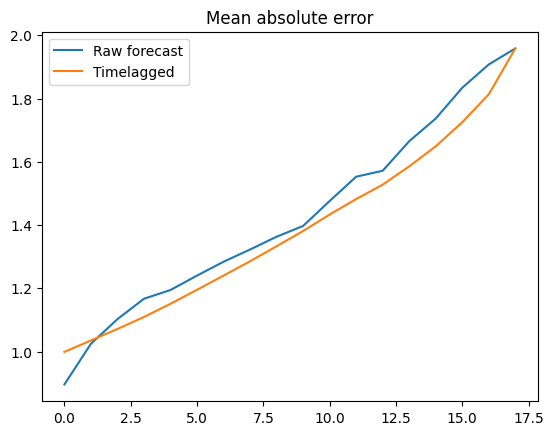

In [12]:
plt.plot([np.abs(by_dt_raw[hour]).mean() for hour in by_dt_raw], label='Raw forecast')
plt.plot([np.abs(by_dt_tl[hour]).mean() for hour in by_dt_raw], label='Timelagged')
plt.title('Mean absolute error')
plt.legend()

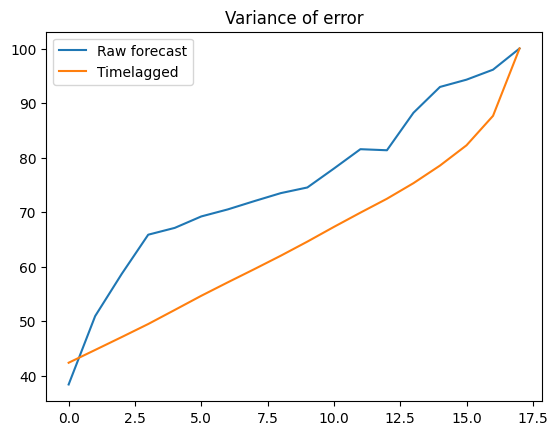

In [13]:
plt.plot([by_dt_raw[hour].var() for hour in by_dt_raw], label='Raw forecast')
plt.plot([by_dt_tl[hour].var() for hour in by_dt_raw], label='Timelagged')
plt.title('Variance of error')
plt.legend()